[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xylem-lab/GEO-ANOM-dashboard/blob/task2/nutrient-balance-2026-11-03/notebooks/13_task2_nutrient_balance.ipynb)

# 13 — Task 2: poultry litter vs what Maryland's cropland can use (Nutrient Balance Map, draft)

**Question.** How much poultry litter do Maryland's houses make, how much can Maryland's cropland use, and where is there more litter than the cropland nearby can take — by how much, and how sure are we? (Planning how litter moves — routes, costs, the most efficient transport — is a later step that builds on these numbers.)

**How.**
1. **Supply** — the frozen Task 1 map (notebook 11): roof area → birds → tons of litter → crop-available N and P₂O₅.
2. **Need** — USDA Cropland Data Layer 2023, every county in Maryland: corn, soybeans, small grains and their double crops, at per-acre rates (soybeans take no N).
3. **The P limit** — cropland already too high in P takes none (share from the Delmarva Land and Litter Collaborative's Maryland fit, 2019); the rest takes P up to crop removal (× a multiplier for the contested "medium" soil category).
4. **Balance in tons of litter** — what the cropland can take is the smaller of the N-based and P-based amounts; surplus = litter − that (negative = room for more). By county, Eastern Shore vs the rest of the state, and on a 5 km grid within hauling distance.
5. **Uncertainty** — every coefficient drawn between its low and high value (2,000 draws). A place is a **robust surplus** if it is in surplus in ≥ 90% of draws: the conclusions that survive every contested assumption (what the DLLC's 2019 effort could not settle).

**Every number comes from the coefficient sheet** (`Task2_results/coefficients.csv` on the shared drive; the repo keeps the defaults in `data/reference/task2_coefficients.csv`). Change a value there, rerun this notebook, and every table and map updates; each run records which sheet it used.

**Draft — internal.** N and P totals stay on the shared drive until the team decides how to present them.

Caveats: Maryland cropland only (Delaware and Virginia are not in the need); the CDL sees most wheat as double-crop wheat/soybeans and little single-crop wheat, so small-grain need is undercounted (conservative); litter also goes on hay and pasture (the "with hay" scenario below); commercial fertilizer and litter already moved are not modelled.

In [1]:
# ── Setup: the same cell works in Google Colab and locally ──────────────────────
import os, sys, json, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
CODE_VERSION = "task2/nutrient-balance-2026-11-03"   # branch, tag or commit to run; the exact commit is recorded in run_meta.json

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # results go to the shared drive's Task1_results
    ROOT = Path("/content/GEO-ANOM-dashboard")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/xylem-lab/GEO-ANOM-dashboard", str(ROOT)], check=True)
    # always bring the copy up to date (a reused Colab session keeps an old copy)
    head = lambda: subprocess.run(["git", "-C", str(ROOT), "rev-parse", "HEAD"], capture_output=True, text=True).stdout
    before = head()
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin"], check=True)
    remote = f"origin/{CODE_VERSION}"
    target = remote if subprocess.run(["git", "-C", str(ROOT), "rev-parse", "-q", "--verify", remote],
                                      capture_output=True).returncode == 0 else CODE_VERSION
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "--detach", target], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-colab.txt")], check=True)
    if head() != before and "geo_anom" in sys.modules:   # new code, but the old version is already loaded
        raise RuntimeError("Code updated. Runtime -> Restart session, then Run all again.")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
# reload edited geo_anom/ code automatically, without restarting the kernel
if "google.colab" not in sys.modules:   # Colab's IPython can't load autoreload on Python 3.12+ (no `imp`)
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)

from geo_anom.task1 import env, region
from geo_anom.task1.pipeline import git_commit
from geo_anom.task1 import county as C
from geo_anom.task2 import cdl, balance as B, nutrients as NU
from shapely.geometry import box
print("running in", "Colab" if IN_COLAB else "local", "| results ->", env.results_root())

running in local | results -> /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task1_results


## Settings

In [2]:
T2 = env.results_root().parent / "Task2_results"          # shared drive, next to Task1_results
SHEET = T2 / "coefficients.csv"                            # Rafi edits this one
OUT = T2 / "draft_v1"
RELEASE = env.results_root() / "final" / "release_v1"     # the frozen Task 1 map
CDL_YEAR = 2023                                            # matches the 2023 photos
CELL_KM, HAUL_KM = 5, 25                                   # map grid; hauling distance for the "within reach" balance
N_DRAWS = 2000                                             # coefficient draws for the uncertainty
ROBUST = 0.90                                              # robust surplus: in surplus in >= 90% of draws
INCLUDE_WEST = False                                       # the 26 houses west of the Bay look like other poultry / idle (notebook 12)
OUT.mkdir(parents=True, exist_ok=True)
if not SHEET.exists():                                     # first run: put the default sheet where Rafi can edit it
    T2.mkdir(parents=True, exist_ok=True); SHEET.write_text(NU.DEFAULT_SHEET.read_text())
    print("created", SHEET, "from the repo defaults")
print("sheet ->", SHEET, "| outputs ->", OUT)

sheet -> /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task2_results/coefficients.csv | outputs -> /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task2_results/draft_v1


## 1. The coefficient sheet

Each coefficient with its low / mid / high value and source. *status* says what it rests on: *literature*, *assumption*, *contested* (DLLC 2019 could not agree), or *confirmed* once Rafi or Extension sets it. Rows that differ from the repo defaults are listed below the table.

In [3]:
sheet = NU.load_coefficients(SHEET)
display(sheet[["low", "mid", "high", "unit", "status", "source"]])
ch = NU.sheet_changes(sheet)
print(f"sheet sha256 {sheet.attrs['sha256'][:12]} |", f"{len(ch)} rows changed from the defaults" if len(ch) else "same as the repo defaults")
if len(ch): display(ch)
V = NU.values(sheet)

,low,mid,high,unit,status,source
name,,,,,,
floor_share,0.90,0.93,0.96,share of roof footprint that is floor,assumption,Task 1 notebook 12
birds_per_ft2,0.90,1.10,1.30,birds per ft2 of floor at placement,literature,NCC Animal Welfare Guidelines (6.5-9 lb/ft2 at...
flocks_per_year,5.00,5.50,6.00,flocks per house per year,literature,Delmarva practice; DCA 2024 (601 M birds / 490...
active_share,0.85,0.93,1.00,share of mapped houses holding birds,assumption,Extension: rusted roofs are not a reliable idl...
litter_lb_per_bird,2.30,2.65,3.00,lb of litter (as removed) per bird marketed,literature,UD Extension (Pokhrel & Shober 2024) 2.3-3 lb/...
N_lb_per_ton,50.00,57.30,64.00,lb total N per wet ton of litter,literature,DLLC 2019 citing CBP Poultry Litter Subcommitt...
P_lb_per_ton,17.00,20.20,23.00,lb P (elemental) per wet ton of litter,literature,DLLC 2019 citing CBP 2015 (DE/MD); litter P fe...
N_available,0.31,0.50,0.70,share of litter N available to the crop in yea...,literature,Tewolde et al. 2013 (31%); Kansas State 45-55%...
corn_N_lb_per_acre,140.00,165.00,190.00,lb N per acre (UMD recommendation by yield goal),literature,UMD yield-goal recommendation ~1 lb N per bush...


sheet sha256 5f3480630de9 | same as the repo defaults


## 2. Supply: litter from the mapped houses

In [4]:
man = json.loads((RELEASE / "MANIFEST.json").read_text())
houses = gpd.read_file(RELEASE / "maryland_poultry_houses.geojson")
assert env.sha256(RELEASE / "maryland_poultry_houses.geojson") == man["files"]["maryland_poultry_houses.geojson"], "release changed since it was frozen"
if not INCLUDE_WEST:
    houses = houses[houses.source != "checked by eye (west of the Bay)"]
md = region.md_counties().to_crs(region.UTM)
md["county"] = np.where(md.NAME.duplicated(keep=False), md.NAMELSAD, md.NAME)
roof_c = houses.groupby("county").roof_m2.sum()
lit = {lev: NU.litter(roof_c.values, NU.values(sheet, lev)) for lev in NU.LEVELS}
sup = pd.DataFrame({"houses": houses.groupby("county").size(), "roof_acres": roof_c / 4046.856,
                    **{f"birds_M_{lev}": lit[lev]["birds_year"] / 1e6 for lev in NU.LEVELS},
                    **{f"litter_kt_{lev}": lit[lev]["tons"] / 1e3 for lev in NU.LEVELS}}).sort_values("houses", ascending=False)
sup.loc["Eastern Shore"] = sup.sum()
display(sup.round(1))
dca = len(houses) * 601e6 / 4909
print(f"cross-check: {len(houses):,} houses x DCA 2024 average (122k birds/house/yr) = {dca / 1e6:.0f} M birds "
      f"-> {dca * 2.3 / 2000 / 1e3:.0f}-{dca * 3.0 / 2000 / 1e3:.0f} kt litter at 2.3-3.0 lb/bird | "
      f"UD: Delmarva >= 686 kt/yr (all three states)")

,houses,roof_acres,birds_M_low,birds_M_mid,birds_M_high,litter_kt_low,litter_kt_mid,litter_kt_high
county,,,,,,,,
Wicomico,602.0,347.0,52.0,79.1,113.2,59.8,104.8,169.8
Worcester,566.0,347.4,52.1,79.2,113.3,59.9,104.9,170.0
Caroline,517.0,323.8,48.6,73.8,105.6,55.8,97.8,158.4
Somerset,474.0,275.8,41.4,62.9,90.0,47.6,83.3,134.9
Dorchester,285.0,176.7,26.5,40.3,57.6,30.5,53.4,86.5
Queen Anne's,220.0,151.5,22.7,34.5,49.4,26.1,45.8,74.1
Talbot,62.0,33.0,4.9,7.5,10.8,5.7,10.0,16.1
Kent,51.0,30.4,4.6,6.9,9.9,5.2,9.2,14.9
Cecil,30.0,20.9,3.1,4.8,6.8,3.6,6.3,10.2


cross-check: 2,807 houses x DCA 2024 average (122k birds/house/yr) = 344 M birds -> 395-515 kt litter at 2.3-3.0 lb/bird | UD: Delmarva >= 686 kt/yr (all three states)


## 3. Need: cropland from the Cropland Data Layer

Acres per county and crop group (30 m pixels binned to 1 km cells, each cell to the county holding its centre). Check: Maryland corn should be near NASS's ~510,000 acres planted in 2023.

In [5]:
info = cdl.ensure_cdl(CDL_YEAR, drive_dir=env.results_root() / "reference")
groups = dict(NU.CROPS, hay=NU.HAY)
crops = {g: cdl.crop_acres_on_grid(info["path"], codes, 1000) for g, codes in groups.items()}
g1 = B.build_grid(B.houses_on_grid(houses, 1000), crops, 1000)
cent = gpd.GeoDataFrame(g1[["cell_id"]], geometry=g1.centroid, crs=region.UTM)
g1["county"] = gpd.sjoin(cent, md[["county", "geometry"]], how="left", predicate="within").county.values
g1 = g1[g1.county.notna()].reset_index(drop=True)        # Maryland only
acols = [f"{g}_acres" for g in groups]
ct = g1.groupby("county")[["houses", "roof_m2"] + acols].sum()
display((ct[acols].sum() / 1e3).round(1).rename("Maryland, thousand acres").to_frame())
acres_c = lambda hay: {g: ct[f"{g}_acres"].values for g in (groups if hay else NU.CROPS)}

,"Maryland, thousand acres"
corn_acres,520.4
soybeans_acres,412.4
small_grains_acres,8.5
small_grain_soy_acres,148.8
small_grain_corn_acres,3.6
corn_soy_acres,0.0
hay_acres,171.0


## 4. County balance

Middle values first (one number per county), then the range over 2,000 draws of every coefficient: 5th–95th percentile and the share of draws in surplus. Negative surplus = room for more litter.

,litter_kt,crop_kac,high_P_share,room_N_kt,room_P_kt,limited_by,surplus_kt,surplus_kt_p5,surplus_kt_p50,surplus_kt_p95,p_surplus,robust_surplus,robust_room
county,,,,,,,,,,,,,
Wicomico,104.83,60.35,0.68,179.24,21.71,P,83.12,51.63,77.69,107.69,1.00,True,False
Somerset,84.86,37.53,0.85,112.22,6.68,P,78.17,55.25,75.56,97.14,1.00,True,False
Worcester,101.72,78.20,0.53,233.88,41.12,P,60.60,24.09,51.86,82.50,1.00,True,False
Caroline,95.43,100.75,0.42,332.95,71.74,P,23.68,-23.28,10.20,42.94,0.70,False,False
Baltimore city,0.00,0.02,0.10,0.07,0.02,P,-0.02,-0.03,-0.03,-0.02,0.00,False,True
Allegany,0.00,1.05,0.10,4.35,1.09,P,-1.09,-1.60,-1.27,-1.02,0.00,False,True
Prince George's,0.00,8.93,0.10,21.98,8.56,P,-8.56,-12.57,-9.98,-8.14,0.00,False,True
Calvert,0.00,8.53,0.10,23.86,8.68,P,-8.68,-12.76,-10.12,-8.27,0.00,False,True
Garrett,0.00,9.69,0.10,42.49,10.32,P,-10.32,-15.22,-12.04,-9.68,0.00,False,True


**Eastern Shore vs the rest of Maryland** (negative surplus = room)

,crop_kac,litter_kt,room_N_kt,room_P_kt,surplus_kt,surplus_kt_p5,surplus_kt_p95
Eastern Shore,706.6,513.4,2236.9,551.3,-37.8,-355.0,56.6
rest of Maryland,387.1,0.0,1286.2,405.8,-405.8,-596.7,-385.0
Maryland,1093.7,513.4,3523.1,957.1,-443.7,-938.2,-345.6


Eastern Shore litter 513 kt (mid); net surplus over the Eastern Shore -38 kt (mid), -355 to 57 kt (p5-p95)
robust surplus counties: Wicomico, Somerset, Worcester
with hay included, robust surplus: Wicomico, Somerset, Worcester


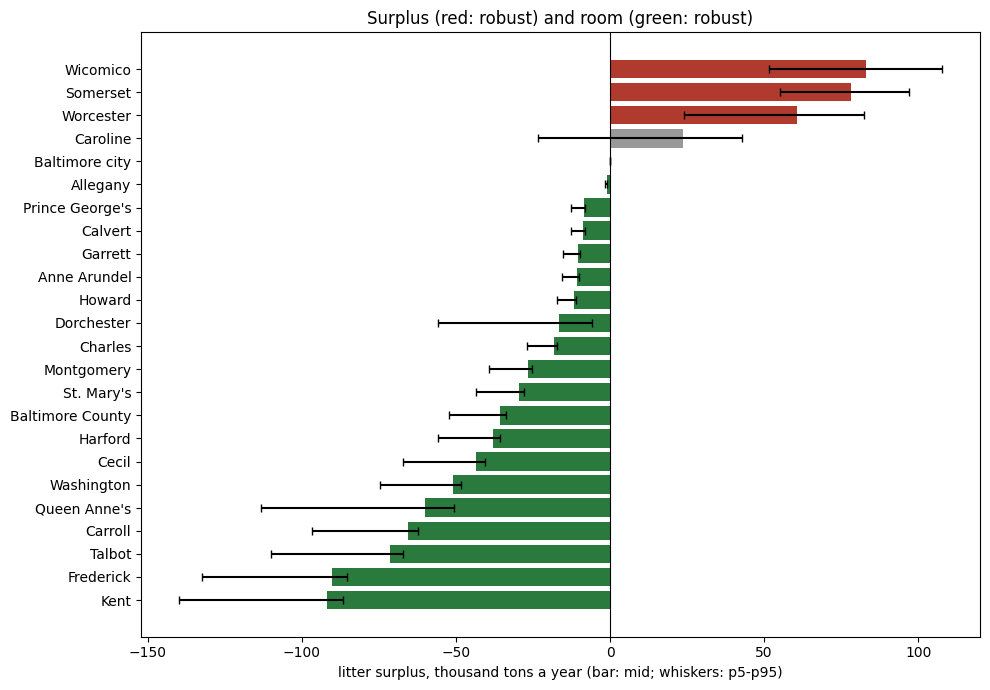

In [6]:
def county_table(hay=False, n=N_DRAWS):
    a = acres_c(hay)
    b = NU.balance(ct.roof_m2.values, a, V)
    mc = NU.monte_carlo(ct.roof_m2.values, a, sheet, n=n)
    t = pd.DataFrame({"litter_kt": b["tons"] / 1e3, "crop_kac": b["crop_acres"] / 1e3, "high_P_share": b["high_P_share"],
                      "room_N_kt": b["capacity_tons_N"] / 1e3, "room_P_kt": b["capacity_tons_P"] / 1e3,
                      "limited_by": np.where(b["P_limits"], "P", "N"), "surplus_kt": b["surplus_tons"] / 1e3}, index=ct.index)
    s = NU.summarize_draws(mc["surplus_tons"] / 1e3, ct.index)
    t = t.join(s.rename(columns={"p5": "surplus_kt_p5", "p50": "surplus_kt_p50", "p95": "surplus_kt_p95"}))
    t["robust_surplus"] = t.p_surplus >= ROBUST
    t["robust_room"] = t.p_surplus <= 1 - ROBUST
    return t.sort_values("surplus_kt", ascending=False), mc

county, mc_c = county_table()
county_hay, _ = county_table(hay=True)
display(county.round(2))
shore = np.where(county.index.isin(C.EASTERN_SHORE), "Eastern Shore", "rest of Maryland")
st = county.groupby(shore)[["crop_kac", "litter_kt", "room_N_kt", "room_P_kt", "surplus_kt"]].sum()
shore_ct = np.where(ct.index.isin(C.EASTERN_SHORE), "Eastern Shore", "rest of Maryland")   # draws are in ct's order
st["surplus_kt_p5"] = [np.percentile(mc_c["surplus_tons"][:, shore_ct == k].sum(axis=1), 5) / 1e3 for k in st.index]
st["surplus_kt_p95"] = [np.percentile(mc_c["surplus_tons"][:, shore_ct == k].sum(axis=1), 95) / 1e3 for k in st.index]
st.loc["Maryland"] = st.sum(); st.loc["Maryland", ["surplus_kt_p5", "surplus_kt_p95"]] = np.percentile(mc_c["surplus_tons"].sum(axis=1), [5, 95]) / 1e3
display(Markdown("**Eastern Shore vs the rest of Maryland** (negative surplus = room)")); display(st.round(1))
es_names = sup.index.drop("Eastern Shore")
tot = mc_c["surplus_tons"][:, ct.index.isin(es_names)].sum(axis=1) / 1e3
print(f"Eastern Shore litter {county.loc[es_names, 'litter_kt'].sum():.0f} kt (mid); net surplus over the Eastern Shore "
      f"{county.loc[es_names, 'surplus_kt'].sum():.0f} kt (mid), {np.percentile(tot, 5):.0f} to {np.percentile(tot, 95):.0f} kt (p5-p95)")
print("robust surplus counties:", ", ".join(county.index[county.robust_surplus]) or "none")
print("with hay included, robust surplus:", ", ".join(county_hay.index[county_hay.robust_surplus]) or "none")
fig, ax = plt.subplots(figsize=(10, 7))
d = county.sort_values("surplus_kt")
ax.barh(d.index, d.surplus_kt, color=np.where(d.robust_surplus, "#b03a2e", np.where(d.robust_room, "#2b7a3d", "0.6")))
ax.errorbar(d.surplus_kt_p50, d.index, xerr=[d.surplus_kt_p50 - d.surplus_kt_p5, d.surplus_kt_p95 - d.surplus_kt_p50], fmt="none", color="k", capsize=3)
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("litter surplus, thousand tons a year (bar: mid; whiskers: p5-p95)")
ax.set_title("Surplus (red: robust) and room (green: robust)"); plt.tight_layout(); plt.show()

## 5. Which assumptions matter?

Each coefficient alone at its low and its high (the rest at mid): the change in the Eastern Shore's net surplus. The top rows are what to pin down with Rafi and Extension first.

,low (kt),high (kt),swing (kt)
coefficient,,,
P_rate_multiplier,-37.8,-313.5,275.6
birds_per_ft2,-166.9,89.7,256.6
P_lb_per_ton,-178.6,53.1,231.7
litter_lb_per_bird,-131.6,55.9,187.5
high_P_offset,-121.2,45.5,166.7
flocks_per_year,-102.4,26.7,129.1
active_share,-98.9,15.6,114.5
corn_P2O5_lb_per_acre,9.0,-84.7,93.7
soy_P2O5_lb_per_acre,4.8,-80.5,85.2


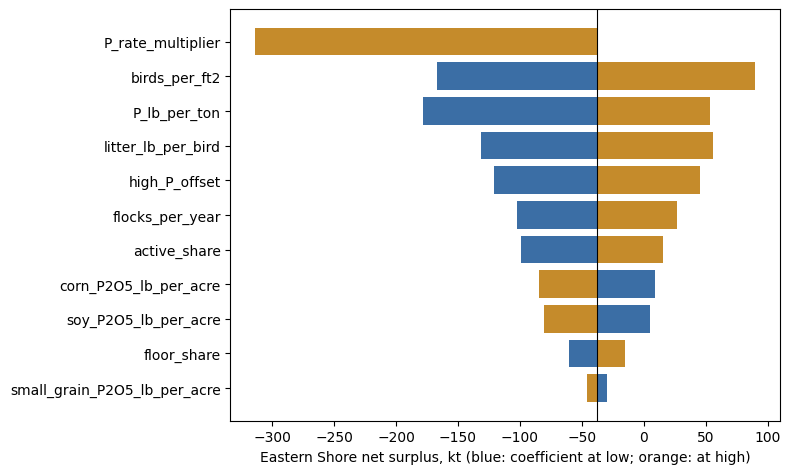

In [7]:
es_mask = ct.index.isin(es_names)
tor = NU.tornado(ct.roof_m2.values[es_mask], {g: v[es_mask] for g, v in acres_c(False).items()}, sheet)
tor = tor[tor.swing > 0]
display((tor.set_index("coefficient")[["low", "high", "swing"]] / 1e3).round(1).rename(columns=lambda c: c + " (kt)"))
fig, ax = plt.subplots(figsize=(8, 0.35 * len(tor) + 1))
base = tor.base.iloc[0] / 1e3
for i, r in tor.iloc[::-1].reset_index(drop=True).iterrows():
    ax.barh(i, r.low / 1e3 - base, left=base, color="#3b6ea5"); ax.barh(i, r.high / 1e3 - base, left=base, color="#c58b2b")
ax.set_yticks(range(len(tor))); ax.set_yticklabels(tor.coefficient.iloc[::-1]); ax.axvline(base, color="k", lw=0.8)
ax.set_xlabel("Eastern Shore net surplus, kt (blue: coefficient at low; orange: at high)"); plt.tight_layout(); plt.show()

## 6. The map: surplus within hauling distance

5 km cells, the whole state. Top: litter. Bottom: for every cell, the litter of all cells within {HAUL_KM} km against the room on all the cropland within {HAUL_KM} km, over the coefficient draws (high-P share from each cell's county). Red = surplus within reach under almost every assumption; green = room.

238 cells with houses; 112 robust surplus within 25 km, holding 56% of the litter


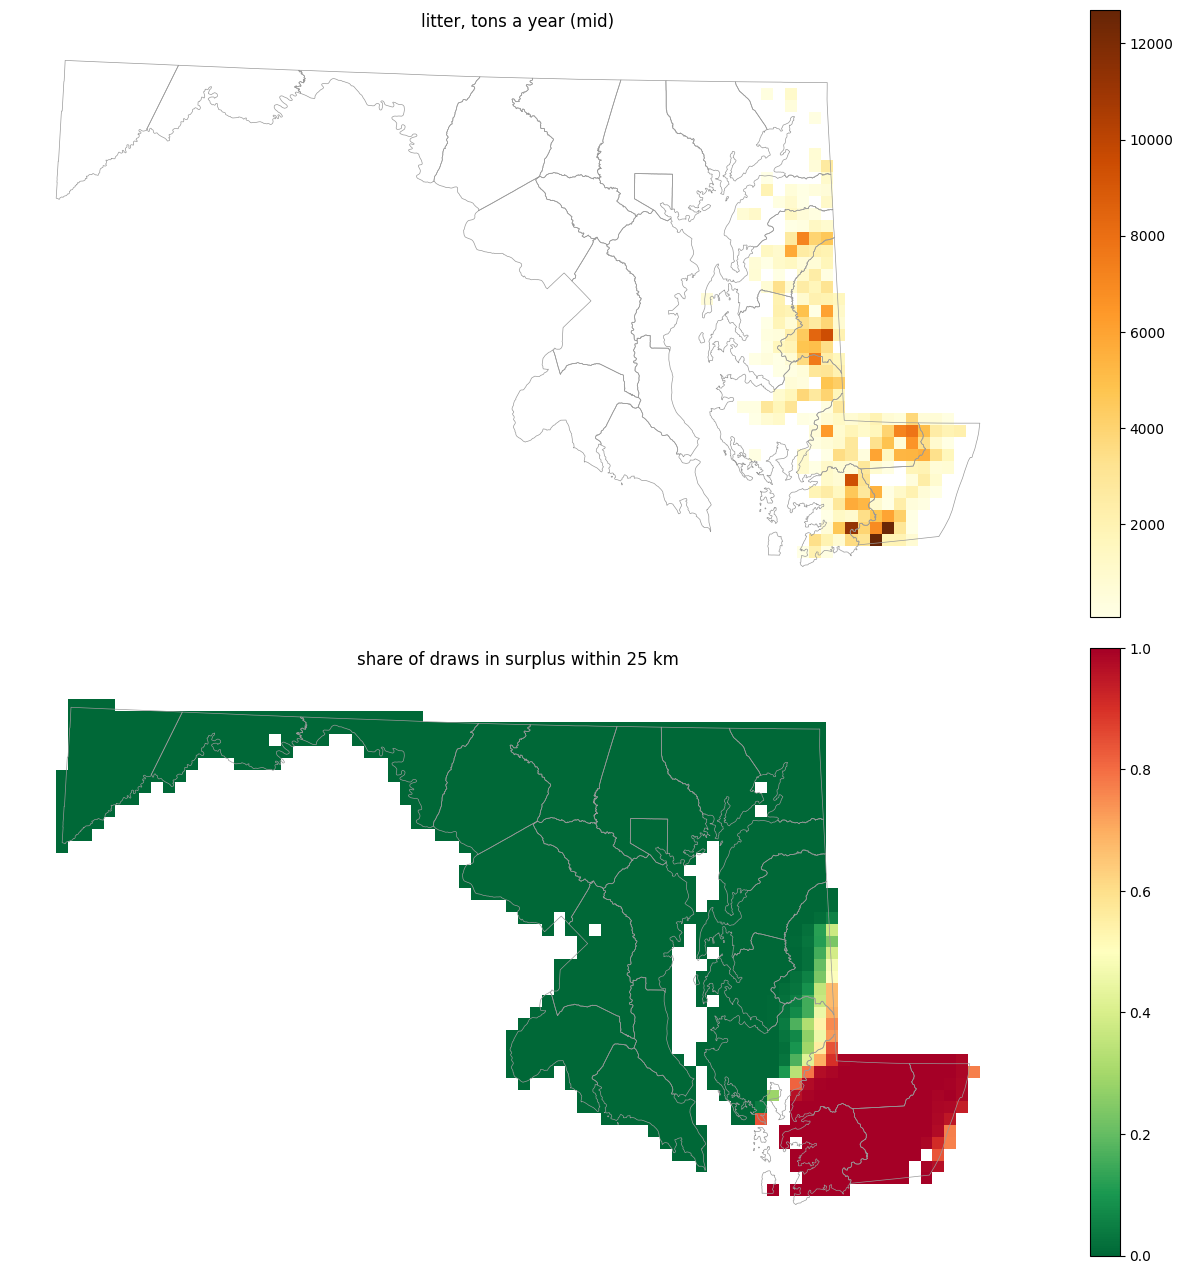

In [8]:
k = CELL_KM
g1["ix5"], g1["iy5"] = g1.ix // k, g1.iy // k
g5 = g1.groupby(["ix5", "iy5"]).agg(houses=("houses", "sum"), roof_m2=("roof_m2", "sum"), county=("county", lambda s: s.mode().iat[0]),
                                     **{c: (c, "sum") for c in acols}).reset_index()
n_grid = min(N_DRAWS, 500)
v = NU.draw(sheet, n_grid, seed=1)
cidx = ct.index.get_indexer(g5.county)
sc, dc = NU.litter(ct.roof_m2.values, v), NU.crop_need(acres_c(False), v)
hiP = NU.high_P_share(sc["P_lb"], dc["crop_acres"], v)[:, cidx]
b5 = NU.balance(g5.roof_m2.values, {g: g5[f"{g}_acres"].values for g in NU.CROPS}, v, hiP)
R = HAUL_KM * 1000; C5 = CELL_KM * 1000
tons_w = NU.within(b5["tons"], g5.ix5, g5.iy5, R, C5)
room_w = NU.within(b5["capacity_tons"], g5.ix5, g5.iy5, R, C5)
g5["litter_t_mid"] = np.median(b5["tons"], axis=0)
g5["surplus_within_t_p50"] = np.median(tons_w - room_w, axis=0)
g5["p_surplus_within"] = ((tons_w - room_w) > 0).mean(axis=0)
g5["robust_surplus_within"] = (g5.p_surplus_within >= ROBUST) & (g5.houses > 0)
g5 = gpd.GeoDataFrame(g5, geometry=[box(i * C5, j * C5, (i + 1) * C5, (j + 1) * C5) for i, j in zip(g5.ix5, g5.iy5)], crs=region.UTM)
hv = g5[g5.houses > 0]
print(f"{len(hv)} cells with houses; {int(hv.robust_surplus_within.sum())} robust surplus within {HAUL_KM} km, holding "
      f"{hv.loc[hv.robust_surplus_within, 'litter_t_mid'].sum() / hv.litter_t_mid.sum():.0%} of the litter")
fig, ax = plt.subplots(2, 1, figsize=(13, 13))
for a, col, cmap, title in [(ax[0], "litter_t_mid", "YlOrBr", "litter, tons a year (mid)"),
                            (ax[1], "p_surplus_within", "RdYlGn_r", f"share of draws in surplus within {HAUL_KM} km")]:
    md.boundary.plot(ax=a, color="0.6", lw=0.5)
    (hv if col == "litter_t_mid" else g5[g5.drop(columns="geometry").filter(like="_acres").sum(axis=1) > 0]).plot(column=col, cmap=cmap, legend=True, ax=a, vmin=0 if col != "litter_t_mid" else None,
                                              vmax=1 if col != "litter_t_mid" else None)
    a.set_axis_off(); a.set_title(title)
plt.tight_layout(); plt.show()

## 7. Save (shared drive only)

In [9]:
county.to_csv(OUT / "county_balance.csv"); county_hay.to_csv(OUT / "county_balance_with_hay.csv")
tor.to_csv(OUT / "which_assumptions_matter.csv", index=False)
st.to_csv(OUT / "eastern_shore_vs_rest.csv")
g5.to_crs(4326).to_file(OUT / f"grid_{CELL_KM}km.geojson", driver="GeoJSON")
sheet.reset_index().to_csv(OUT / "coefficients_used.csv", index=False)
meta = {"made_at": pd.Timestamp.now().isoformat(timespec="seconds"), "git_commit": git_commit(), "notebook": "13_task2_nutrient_balance",
        "sheet": str(SHEET), "sheet_sha256": sheet.attrs["sha256"], "changed_from_defaults": ch.index.tolist(),
        "task1_release_manifest_sha256": env.sha256(RELEASE / "MANIFEST.json"), "cdl": info,
        "settings": {"cell_km": CELL_KM, "haul_km": HAUL_KM, "n_draws": N_DRAWS, "robust": ROBUST, "include_west": INCLUDE_WEST}}
(OUT / "run_meta.json").write_text(json.dumps(meta, indent=2, default=str))
print("saved to", OUT)

saved to /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task2_results/draft_v1


## What this shows (draft v1, coefficient sheet = repo defaults)

1. **Supply:** the 2,807 Eastern Shore houses make **~515 thousand tons of litter a year** (294–835 kt across the coefficient ranges). Cross-check: houses × DCA's 2024 average birds per house × 2.3–3.0 lb/bird = 395–515 kt.
2. **Need, whole state:** 1.09 million acres of corn, soybeans, small grains and double crops (CDL 2023): 707k on the Eastern Shore, 387k in the rest of Maryland.
3. **Balance, whole state:** Maryland's cropland can take more litter than the houses make — net **−444 kt** (room; −938 to −346 kt). The Eastern Shore alone is roughly balanced (**−38 kt**, −355 to +57 kt); the rest of Maryland has **~406 kt** of room (385–597 kt) and almost no litter.
4. **Where the surplus is:** **Wicomico, Somerset and Worcester are a surplus under every assumption** (100% of 2,000 draws; mid 61–83 kt each). **Caroline** is uncertain (70% of draws). Every other county has room under every assumption. Including hay doesn't change this. On the 5 km grid, the cells within 25 km of the lower-Shore houses are a surplus in almost every draw; they hold 56% of the litter.
5. **P sets the limit everywhere, not N.** In the surplus counties, 53–85% of cropland is estimated too high in P to take any (DLLC's Maryland fit), so the contested N numbers (first-year availability 31–70%) don't change where the surplus is.
6. **What to pin down first** (biggest swing in the Eastern Shore balance): the P rate on soils below the high-P threshold (the DLLC's contested "medium vs optimum" point, 276 kt), stocking density (257 kt), P per ton of litter (232 kt), litter per bird (188 kt), the high-P share (167 kt) — the questions for Rafi and Extension.

These are the numbers; how litter is moved from surplus to room (routes, costs, efficient transport) is a later step built on them.

Caveats: Maryland cropland only (Delaware cropland next to the lower Shore would also take litter); CDL undercounts wheat (conservative); county-level high-P share applied to every cell in a county (sharp county lines on the map); commercial fertilizer and litter already moved are not modelled; draft — internal until the team decides how to present N and P.
